In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb

## Data Integration


Load Data Echocardiogram

In [8]:
# 1. Membaca data secara langsung dari UCI ML Repository dengan penanganan missing value yang benar
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/echocardiogram/echocardiogram.data"
columns = [
    'Survival', 'StillAlive', 'AgeAtHeartAttack', 'PericardialEffusion',
    'FractionalShortening', 'Epss', 'Lvdd', 'WallMotionScore',
    'WallMotionIndex', 'Mult', 'Name', 'Group', 'AliveAt1'
]

# Memuat data dengan na_values='?' untuk otomatis mendeteksi missing value
data_raw = pd.read_csv(url, names=columns, na_values='?', on_bad_lines='skip')

# Drop baris target utama (StillAlive) yang kosong
data_clean = data_raw.dropna(subset=['StillAlive']).copy()

# Drop kolom yang tidak relevan dengan pemodelan medis klinis langsung
data_clean = data_clean.drop(columns=['Name', 'Group', 'AliveAt1'], errors='ignore')

print(f"Data berhasil dimuat! Dimensi akhir: {data_clean.shape}")
data_clean.head()

Data berhasil dimuat! Dimensi akhir: (131, 10)


,Survival,StillAlive,AgeAtHeartAttack,PericardialEffusion,FractionalShortening,Epss,Lvdd,WallMotionScore,WallMotionIndex,Mult
0,11.0,0,71.0,0,0.260,9.000,4.600,14.0,1.00,1.000
1,19.0,0,72.0,0,0.380,6.000,4.100,14.0,1.70,0.588
2,16.0,0,55.0,0,0.260,4.000,3.420,14.0,1.00,1.000
3,57.0,0,60.0,0,0.253,12.062,4.603,16.0,1.45,0.788
4,19.0,1,57.0,0,0.160,22.000,5.750,18.0,2.25,0.571


##Data Transformation

In [9]:
discrete_features = ['PericardialEffusion']
continuous_features = data_clean.drop(columns=['PericardialEffusion', 'StillAlive']).columns
label = ['StillAlive']

print(continuous_features)

Index(['Survival', 'AgeAtHeartAttack', 'FractionalShortening', 'Epss', 'Lvdd',
       'WallMotionScore', 'WallMotionIndex', 'Mult'],
      dtype='object')


In [10]:
data_clean.shape

(131, 10)

In [11]:
for feature in discrete_features:
    data_clean[feature] = data_clean[feature].fillna(data_clean[feature].mode()[0])

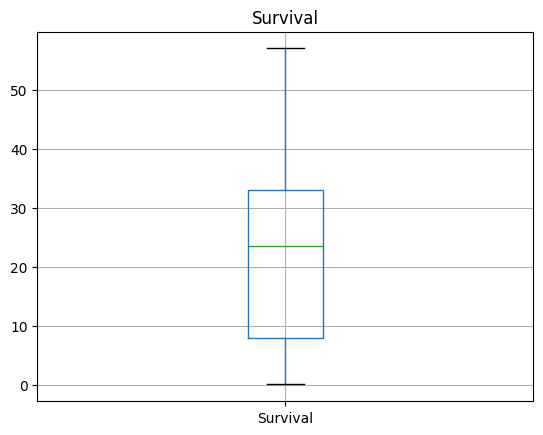

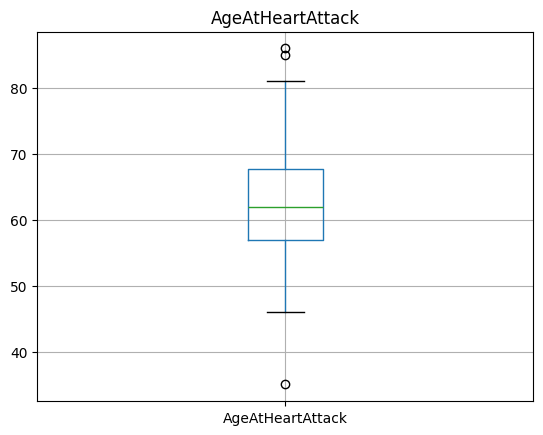

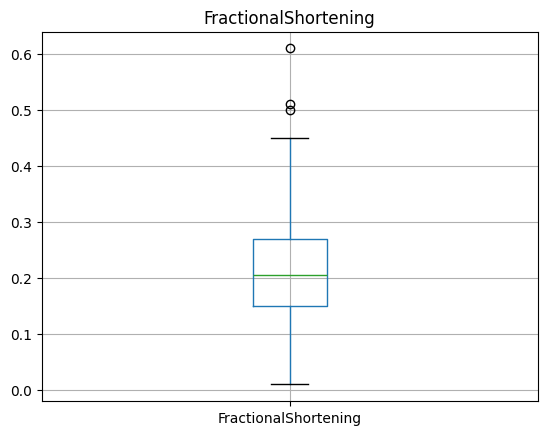

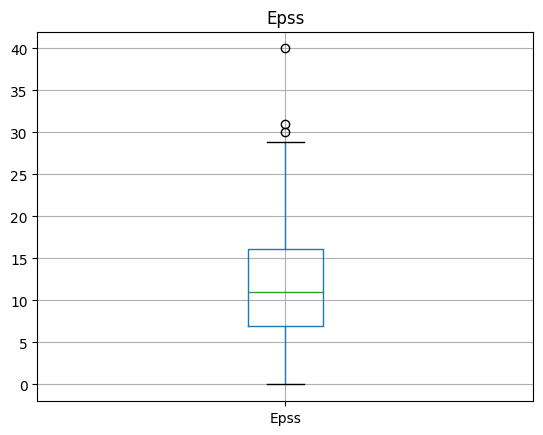

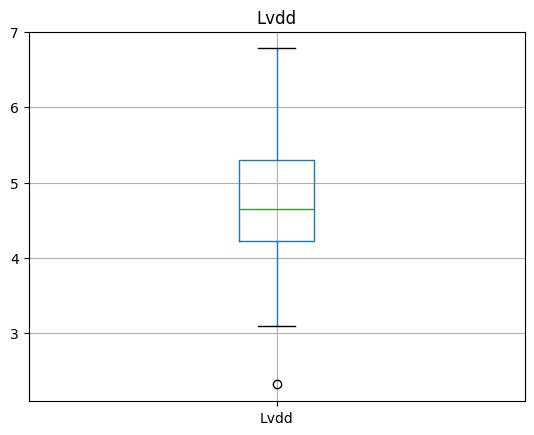

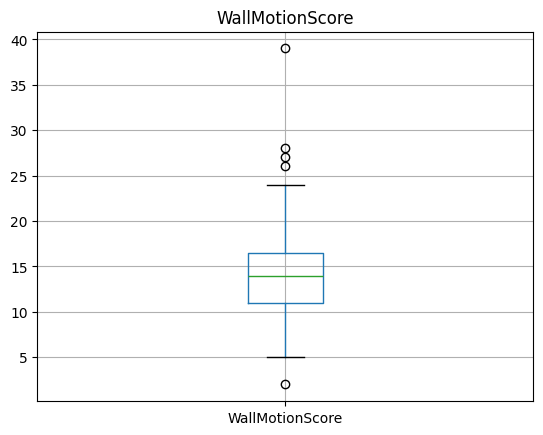

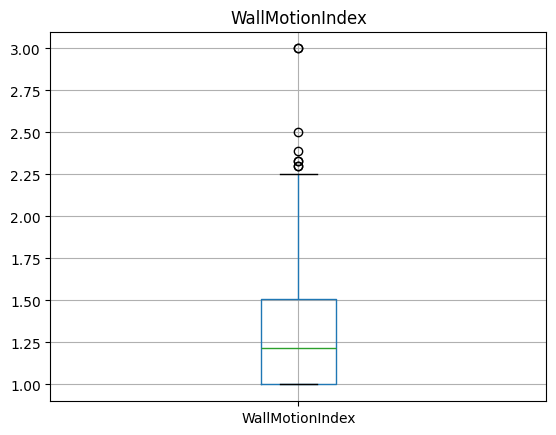

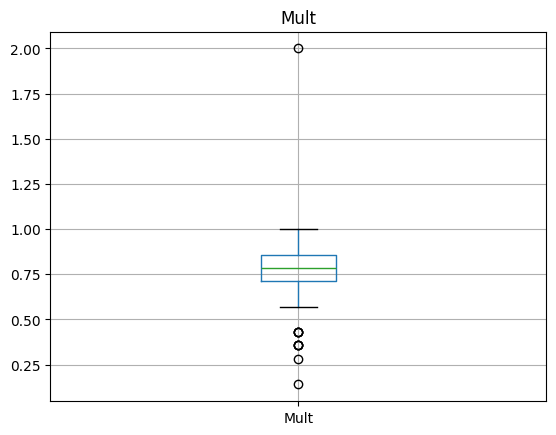

In [12]:
for feature in continuous_features:
    data_clean.boxplot(feature)
    plt.title(feature)
    plt.show()

## Data Transformation and Data Discretization

In [13]:
features_with_outliers = ['WallMotionScore', 'WallMotionIndex', 'Mult']

In [14]:
for feature in continuous_features:
    if feature in features_with_outliers:
        data_clean[feature] = data_clean[feature].fillna(data_clean[feature].median())
    else:
        data_clean[feature] = data_clean[feature].fillna(data_clean[feature].mean())

In [15]:
data_clean.shape

(131, 10)

In [16]:
from sklearn.neighbors import LocalOutlierFactor
lof = LocalOutlierFactor()
outliers_rows = lof.fit_predict(data_clean)

In [17]:
mask = outliers_rows != -1

In [18]:
data_clean.isnull().sum()

,0
Survival,0
StillAlive,0
AgeAtHeartAttack,0
PericardialEffusion,0
FractionalShortening,0
Epss,0
Lvdd,0
WallMotionScore,0
WallMotionIndex,0
Mult,0


In [19]:
data_clean.shape

(131, 10)

## Model Training and Evaluation

In [20]:
# 1. Menyiapkan fitur murni tanpa target leakage ('Survival' dihapus)
X_final = data_clean.drop(columns=['StillAlive', 'Survival'], errors='ignore')
y_final = data_clean['StillAlive']

# Identifikasi tipe kolom
discrete_cols = ['PericardialEffusion']
num_cols = [col for col in X_final.columns if col not in discrete_cols]

# 2. Definisikan Pipeline Pra-pemrosesan
preprocessor_final = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols)
], remainder='passthrough')

# 3. Definisikan skema CV
cv_final = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)

# 4. Melakukan Hyperparameter Tuning XGBoost secara aman di dalam Pipeline
xgb_pipeline = Pipeline([
    ('pre', preprocessor_final),
    ('clf', xgb.XGBClassifier(random_state=0))
])

param_distributions = {
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'clf__max_depth': [3, 4, 5, 6, 7],
    'clf__min_child_weight': [1, 3, 5],
    'clf__gamma': [0.0, 0.1, 0.2, 0.3, 0.4]
}

tuned_xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=cv_final,
    scoring='accuracy',
    n_jobs=-1,
    random_state=0
)
tuned_xgb_search.fit(X_final, y_final)

best_xgb_model = tuned_xgb_search.best_estimator_['clf']
print("XGBoost Hyperparameter Terbaik:", tuned_xgb_search.best_params_)

XGBoost Hyperparameter Terbaik: {'clf__min_child_weight': 5, 'clf__max_depth': 3, 'clf__learning_rate': 0.2, 'clf__gamma': 0.1}


In [21]:
# 5. Evaluasi Ulang Semua Model secara Adil (Tanpa Target Leakage)
models_final = {
    'Baseline (Most Frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=500, class_weight='balanced', random_state=0),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=0),
    'Random Forest': RandomForestClassifier(max_depth=4, class_weight='balanced', random_state=0),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, random_state=0),
    'Tuned XGBoost': best_xgb_model
}

final_results = []

for name, model in models_final.items():
    pipeline_eval = Pipeline([
        ('pre', preprocessor_final),
        ('clf', model)
    ])

    scores = cross_validate(pipeline_eval, X_final, y_final, cv=cv_final, scoring=['accuracy', 'f1', 'roc_auc'], n_jobs=-1)

    final_results.append({
        'Model': name,
        'Accuracy (%)': round(scores['test_accuracy'].mean() * 100, 2),
        'F1-Score (%)': round(scores['test_f1'].mean() * 100, 2),
        'ROC-AUC (%)': round(scores['test_roc_auc'].mean() * 100, 2)
    })

df_final_performance = pd.DataFrame(final_results)
display(df_final_performance)

,Model,Accuracy (%),F1-Score (%),ROC-AUC (%)
0,Baseline (Most Frequent),67.18,0.00,50.00
1,Logistic Regression,72.22,59.85,76.74
2,Decision Tree,61.69,52.37,62.45
3,Random Forest,70.86,54.68,75.08
4,Gradient Boosting,66.11,44.44,67.57
5,Tuned XGBoost,69.01,48.02,72.65


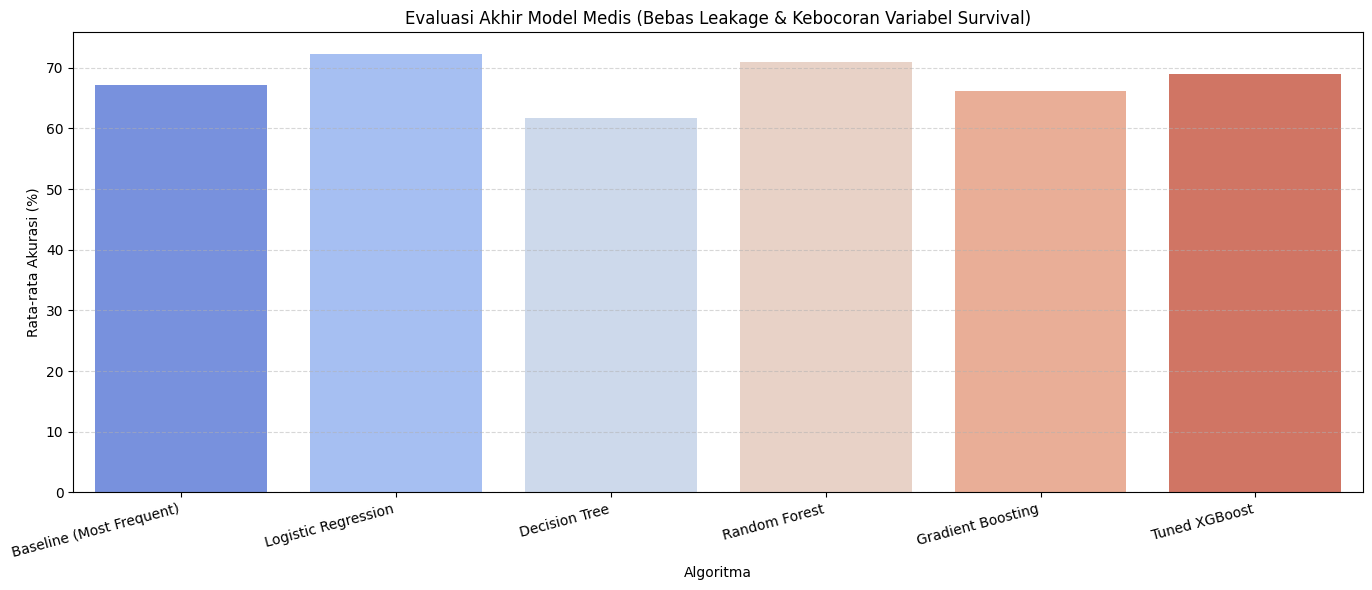

In [22]:
# 6. Visualisasi Perbandingan Metrik Akhir
plt.figure(figsize=(14, 6))
sns.barplot(x='Model', y='Accuracy (%)', data=df_final_performance, hue='Model', palette='coolwarm', legend=False)
plt.title('Evaluasi Akhir Model Medis (Bebas Leakage & Kebocoran Variabel Survival)')
plt.ylabel('Rata-rata Akurasi (%)')
plt.xlabel('Algoritma')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()